# Week 4 Capstone — Predicting Internship Selection Outcomes

**Author:** Snethemba Asande Mthembu  |  **Programme:** NextGen Learners Data Science Internship

This notebook is written as a report. It takes the cleaned applicant data from Weeks 1–3, adds four **simulated** features, trains a Logistic Regression model to predict whether an applicant is *Selected*, evaluates it honestly, and ends with a plain-language Executive Summary.

**Sections**
1. Set up
2. Load and tidy the cleaned data
3. Extend the dataset with simulated features
4. Feature preparation
5. Train / test split
6. Train the model
7. Evaluate the model
8. Limitations
9. Which features mattered?
10. Executive Summary

## 1. Set Up

Importing the libraries used throughout the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Load and Tidy the Cleaned Data

`applicants_cleaned.csv` is the output of the Week 1 cleaning work (77 applicants). A few small inconsistencies were still present (extra spaces, `selected` vs `Selected`, `data science` vs `Data Science`), so we standardise text in the columns we need. The identifier columns (name, email, phone) are kept only for reference — they are **not** used for modelling.

In [2]:
df = pd.read_csv('applicants_cleaned.csv')

# Standardise whitespace and capitalisation in the text columns we rely on
for col in ['Applicant Name', 'Domain Applied', 'University', 'Status']:
    df[col] = df[col].str.strip()
df['Status'] = df['Status'].str.title()
df['Domain Applied'] = df['Domain Applied'].str.title()

print(df.shape)
print(df['Status'].value_counts())
print()
print(df['Domain Applied'].value_counts())

(77, 7)
Status
Under Review    33
Rejected        23
Selected        21
Name: count, dtype: int64

Domain Applied
Web Development         20
Software Engineering    20
Data Science            15
Data Analytics          12
Cybersecurity            9
Graphic Design           1
Name: count, dtype: int64


## 3. Extend the Dataset with Simulated Features

> **Honesty note:** the four features below are **simulated, not real historical data**. We do not have real records of applicants' skills, portfolios, hackathon history or statement quality, so they are generated with random numbers (`np.random.seed(42)` makes them reproducible). In a real NextGenLearners deployment this information would have to be collected from actual applications before the model could be trusted.

Important consequence: because these values are random and were generated *independently of* the real `Status`, they cannot genuinely explain who was selected. We should expect the model to perform close to guessing, and we report whatever it actually does.

| Feature | Type | How it is simulated |
|---|---|---|
| `num_skills_listed` | number | random integer 1–8 |
| `has_portfolio` | Yes/No | 40% Yes |
| `prior_hackathon_participation` | Yes/No | 30% Yes |
| `statement_quality_score` | number | random integer 1–10 |

In [3]:
np.random.seed(42)  # reproducible "random" values

df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.4, 0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size=len(df), p=[0.3, 0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

df[['Applicant Name', 'Domain Applied', 'Status', 'num_skills_listed', 'has_portfolio',
    'prior_hackathon_participation', 'statement_quality_score']].head()

,Applicant Name,Domain Applied,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Nandi Ndlovu,Cybersecurity,Under Review,7,Yes,No,7
1,David Adams,Data Science,Under Review,4,No,Yes,9
2,Thando Mthembu,Web Development,Under Review,5,No,No,9
3,Nomsa Naidoo,Data Analytics,Selected,7,No,No,3
4,Peter Brown,Web Development,Selected,3,Yes,No,3


## 4. Feature Preparation

Models can only work with numbers, so this section converts everything into numeric form.

**4.1 Yes/No → 1/0.** A model can use 1/0 mathematically; it cannot interpret the word "Yes".

**4.2 Target column.** `target = 1` if the applicant was *Selected*, otherwise `0`.

**4.3 Remove "Under Review" rows.** Those applicants have no final decision yet, so there is no confirmed outcome to learn from. Training on them as if they were "not selected" would teach the model something false.

**4.4 One-hot encode `Domain Applied`.** Domains have no natural order, so giving them numbers 1, 2, 3 would wrongly imply one is "more" than another. One-hot encoding creates a separate 0/1 column per domain. We use `drop_first=True`, which drops one domain (Cybersecurity, first alphabetically) and treats it as the baseline represented by all zeros; this avoids redundant columns that can confuse the model.

In [4]:
# 4.1 Yes/No -> 1/0
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No': 0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No': 0})

# 4.2 Target: 1 = Selected, 0 = anything else
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)

# 4.3 Keep only applicants with a final decision
df_model = df[df['Status'] != 'Under Review'].copy()
print("Rows with a final decision:", len(df_model))
print(df_model['target'].value_counts().rename({1: 'Selected', 0: 'Rejected'}))

# 4.4 One-hot encode the domain
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)
print()
print([c for c in df_model.columns if c.startswith('Domain Applied_')])

Rows with a final decision: 44
target
Rejected    23
Selected    21
Name: count, dtype: int64

['Domain Applied_Data Analytics', 'Domain Applied_Data Science', 'Domain Applied_Software Engineering', 'Domain Applied_Web Development']


### Choosing the final features

We use the four simulated features plus the one-hot domain columns. We deliberately **exclude** Applicant Name, Email and Phone (identifiers with no genuine predictive meaning; using them would be useless and inappropriate), Application Date, and University. University is left out to avoid building a model that could favour or penalise applicants by institution, which would raise fairness concerns (see Limitations).

In [5]:
feature_columns = ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation',
                   'statement_quality_score'] + [c for c in df_model.columns if c.startswith('Domain Applied_')]

X = df_model[feature_columns].astype(float)
y = df_model['target']
print(X.shape)
feature_columns

(44, 8)


['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Data Analytics', 'Domain Applied_Data Science', 'Domain Applied_Software Engineering', 'Domain Applied_Web Development']

## 5. Train / Test Split

If we trained and tested on the same applicants, the model could simply memorise the answers, like grading a student on the exact questions they studied. We hold back 20% of the data as a **test set** the model never sees while learning. `random_state=42` makes the split reproducible.

(The guide's example shows `random_state=424`, which looks like a typo for 42, so 42 is used here.)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Test rows:    ", len(X_test))
print("Selected in test set:", int(y_test.sum()), "of", len(y_test))

Training rows: 35
Test rows:     9
Selected in test set: 2 of 9


**The test set is very small (9 applicants, only 2 of whom were Selected).** Every metric below can change a lot with just one or two different predictions, so treat them as an illustration of the method rather than a reliable measurement.

## 6. Train the Model

We use **Logistic Regression**, the standard simple model for yes/no outcomes. `.fit()` is the learning step: the model looks at the training features (`X_train`) alongside the correct answers (`y_train`) and adjusts its internal numbers to link the two. It then predicts outcomes for the unseen test applicants.

In [7]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Predictions:", y_pred.tolist())
print("Actual:     ", y_test.tolist())

Predictions: [1, 1, 1, 1, 1, 0, 1, 1, 1]
Actual:      [1, 0, 0, 0, 0, 0, 0, 1, 0]


## 7. Evaluate the Model

### 7.1 Accuracy
Accuracy is the share of test applicants the model got right (Selected or Not Selected). On its own it can mislead, especially with small or imbalanced data, so we also report precision, recall and a confusion matrix.

In [8]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 33.33%


### 7.2 Precision, Recall and the Confusion Matrix

- **Precision:** of the applicants the model predicted would be *Selected*, what share really were?
- **Recall:** of the applicants who were really *Selected*, what share did the model catch?
- **Confusion matrix:** a 2×2 grid counting the four kinds of outcome (correct "Selected", correct "Not Selected", false alarms, and missed selections).

Precision: 25.00%
Recall:    100.00%


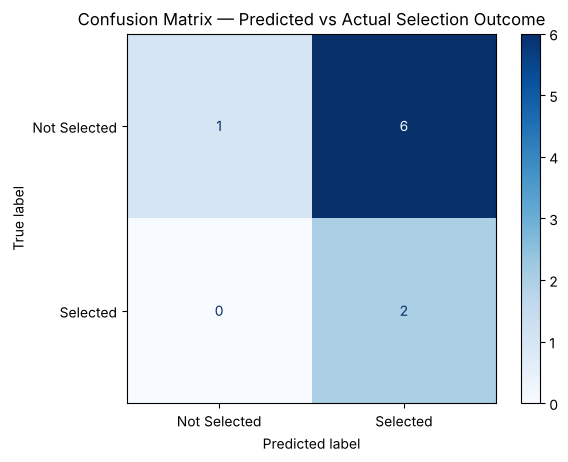

In [9]:
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred)
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected', 'Selected'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Predicted vs Actual Selection Outcome')
plt.show()

**What these numbers say.** The model got only **3 of 9** test applicants right (accuracy 33.3%). It caught **both** of the 2 applicants who were actually Selected (recall 100%), but only because it predicted "Selected" for almost everyone: it flagged **8** applicants as likely to be selected, and just 2 of them were (precision 25%). Of the 7 applicants who were *not* selected, it correctly identified only 1 and wrongly flagged 6.

That is no better than guessing, and it is what we expected given that the input features are random. High recall here is not a sign of skill, it is a side-effect of over-predicting "Selected".

### 7.3 A Sanity Check: Is Any of This Reliable?

Because the test set is so small, here are two extra checks: how accuracy changes across 20 different random splits, and how the model compares with a naive baseline that always predicts the most common outcome ("Rejected").

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Accuracy across 20 different train/test splits
accs = []
for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed)
    accs.append(LogisticRegression(max_iter=1000).fit(Xa, ya).score(Xb, yb))
print(f"Accuracy over 20 different splits: mean {np.mean(accs):.1%}, min {min(accs):.1%}, max {max(accs):.1%}")

# 5-fold cross-validation vs a 'always predict the majority class' baseline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_cv = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=cv).mean()
baseline_cv = cross_val_score(DummyClassifier(strategy='most_frequent'), X, y, cv=cv).mean()
print(f"5-fold cross-validated accuracy: model {model_cv:.1%} vs always-'Rejected' baseline {baseline_cv:.1%}")

Accuracy over 20 different splits: mean 38.9%, min 0.0%, max 55.6%
5-fold cross-validated accuracy: model 45.3% vs always-'Rejected' baseline 52.2%


Across different splits the accuracy swings widely (anywhere from 0% to about 56%), and the cross-validated accuracy (about 45%) is **below** the do-nothing baseline of about 52%. Honest conclusion: **with these features the model has no real predictive ability.** That is the correct and expected result for random inputs, and it is why we must not read the feature rankings below as real findings.

## 8. Limitations (Honest Assessment)

- **Small and partly simulated data.** Only 44 applicants had a final decision, and four of the features were artificially generated, not real historical behaviour.
- **Unstable results.** With a 9-row test set, results move noticeably if the data is split differently (section 7.3). These numbers illustrate the *method*; they are not a production-ready guarantee.
- **Status itself has no real signal.** The underlying applicant records come from the Week 1 practice dataset, where statuses were assigned at random, so there is nothing real for any model to find.
- **Repeated applicants.** The same people (12 distinct names) appear in several rows with different domains, so the same person can land in both the training and test sets. That makes evaluation look slightly more optimistic than it should.
- **Bias risk.** A model trained on past selection decisions can learn and repeat any bias in them (for example if certain universities or domains were favoured for reasons unrelated to merit). This is a genuine concern for any selection tool and should never be glossed over. University was deliberately excluded here, but it is not a complete protection, because other features can act as stand-ins.
- **Decision-support only.** A model like this should help human reviewers, never replace them.

## 9. Which Features Mattered Most?

For Logistic Regression we read the **coefficients**. A positive coefficient means that as the feature goes up (or is "yes"), the model's predicted chance of "Selected" goes up; a negative coefficient means the opposite. Larger absolute values mean more influence in the model.

                            Feature  Coefficient
     Domain Applied_Web Development     0.320190
                  num_skills_listed     0.162719
            statement_quality_score     0.084702
                      has_portfolio     0.038912
      Domain Applied_Data Analytics    -0.170866
      prior_hackathon_participation    -0.289386
        Domain Applied_Data Science    -0.370233
Domain Applied_Software Engineering    -0.562238


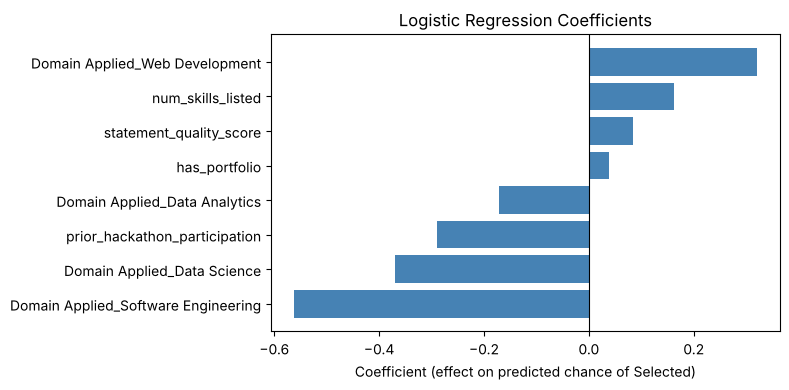

In [11]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)
print(coefficients.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.barh(coefficients['Feature'][::-1], coefficients['Coefficient'][::-1], color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (effect on predicted chance of Selected)')
plt.title('Logistic Regression Coefficients')
plt.tight_layout()
plt.show()

**Interpretation.** In this model, applying for Web Development (0.32 vs the Cybersecurity baseline) and a higher skill count (0.16) pushed the predicted chance of selection up the most, while applying for Software Engineering (−0.56), Data Science (−0.37) and prior hackathon participation (−0.29) pushed it down. `has_portfolio` and `statement_quality_score` had almost no influence (0.04 and 0.08).

**Be careful with this.** These are simply the patterns the model picked up from this particular small dataset, and given section 7.3 they are almost certainly noise. In particular, a *negative* effect for hackathon experience makes no practical sense, which is a good hint that the pattern is chance. This is not a finding about how NextGenLearners really selects interns, and it would need to be validated on real historical data.

## 10. Executive Summary

**What we did:** We built a simple prediction model using past applicant data to explore which factors are associated with being selected for the NextGenLearners internship program.

**What we found:** The model correctly predicted the outcome for about 33% of applicants in our test group (3 out of 9), which is no better than guessing, and a simple "always predict rejected" rule would have scored higher. Its apparent top factors (the domain applied for and the number of skills listed) should not be trusted, because the model showed no real ability to tell selected and rejected applicants apart.

**Important caveats:** This analysis used a small, partly simulated dataset. Several factors (like skill count, portfolio and statement quality) were artificially generated for this exercise rather than pulled from real records, and only 44 applicants had a final decision, so the test group was just 9 people. Before using anything like this for real decisions, NextGenLearners would need to collect this information consistently from real applications and check the model on a much larger, real dataset. The model should only ever assist reviewers, never replace human judgment, especially given the risk that it could unintentionally repeat biases from past decisions.

**Recommendation:** Add required fields to the application form for a portfolio/GitHub link, a skills list and a short statement scored by reviewers against a fixed rubric, and keep them for at least one full intake cycle. Then repeat this analysis on that real data (ideally 200+ decided applicants) before deciding whether any prediction tool is worthwhile.